In [1]:
import pandas as pd
import re
import os #pour naviguer dans les dossiers
from io import StringIO
import s3fs #pour connecter au bucket

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:


# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})

BUCKET_OUT = "aluneau"

last_file="anonymous_answer_2026-07-24.csv"


In [7]:
with fs.open(f"{BUCKET_OUT}/data_eP8/raw/{last_file}", "r") as file_in:
    df0 = pd.read_csv(file_in, sep =",")

df01 = df0.loc[~df0.q45_clé.isin(["Z37Y-6JGC","QNYZ-3MH2","H5X6-KL2Z",'PS8W-TJ9P'])].drop_duplicates(subset="q45_clé")#.merge(list_affil, on = ["q45_clé", "q44_ufr_labo"], how = "left")
df01

,qno_obs,q1_so_principles,q2_hal_depot,q3_octavi_depot,q4_diff_data,q4_autres_entrepots,q5_r,q5_python,q5_excel,q5_julia,...,partition_1,label_recherche_1,auto_lab_research_cluster,research_fields,clust_type_data,auto_clust_data,label_clust_metho_data_kneig_4,auto_metho_data_kneig_4,label_clust_metho_data_kneig_5,auto_metho_data_kneig_5
1,2,"Oui, un peu","Oui, une fois",Non,Non,NaN,Non,Non,Non,Non,...,4.0,Etudes sociales des oeuvres culturelle,"[""SH4 L'esprit humain et sa complexité"", 'SH8 ...","['SH3', 'SH4', 'SH5', 'SH6']",Corpus textuels,"['Données textuelles ou documentaires', 'Métad...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Collecte et analyse de traces numériques,"Données statistiques, python, Données du web"
2,3,"Oui, tout à fait","Oui, plusieurs fois",Je ne connais pas Octaviana,Non,NaN,Non,Non,Oui,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Entretiens,"['Données textuelles ou documentaires', 'Autre...",Enquêtes qualitatives et entretien,"Données textuelles ou documentaires, Données d...",Enquête par entretien,"Données textuelles ou documentaires, excel, Do..."
3,4,"Oui, un peu","Oui, une fois",Non,"Autre, précisez",OSF,Oui,Non,Non,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...",['SH4'],Etudes expérimentale,"[""Données expérimentales ou d'observation"", ""D...",Analyse de données expérimentales,"Données statistiques, Données expérimentales o...",Approches expérimentales,"Données statistiques, r, excel"
4,5,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Non,Non,Oui,Non,...,3.0,Histoires sociales du politique,"['SH8 Études des cultures et des arts', ""SH6 L...","['SH1', 'SH3', 'SH6', 'SH8']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes,"excel, Métadonnées, Données statistiques",Enquête par entretien,"Données textuelles ou documentaires, excel, Do..."
5,6,"Oui, un peu","Oui, systématiquement",Non;Je ne connais pas Octaviana,Non,NaN,Oui,Non,Oui,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['LS4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
114,117,"Oui, un peu","Oui, plusieurs fois",Non,"Autre, précisez",OSF,Oui,Oui,Oui,Non,...,5.0,Psychologie,"[""SH4 L'esprit humain et sa complexité"", 'LS5 ...","['SH4', 'LS5']",Données statistiques et observations,"['Données statistiques', ""Données expérimental...",Approches expérimentales/cliniques,"Données expérimentales ou d'observation, excel, r",Approches expérimentales,"Données statistiques, r, excel"
115,118,"Oui, un peu","Oui, systématiquement",Non,Non,NaN,Oui,Non,Oui,Non,...,0.0,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH2', 'SH3', 'SH7']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do..."
116,119,"Oui, un peu","Oui, plusieurs fois",Non,Non,NaN,Oui,Non,Oui,Non,...,0.0,"Individus, normes, société","['SH2 Institutions, gouvernance et systèmes ju...","['SH1', 'SH2', 'SH3', 'SH7']",Données statistiques et textutelles,"['Données statistiques', 'Données textuelles o...",Méthodes mixtes II,"Données statistiques, Données textuelles ou do...",Méthodes mixtes,"Données statistiques, Données textuelles ou do..."
117,120,Non,"Oui, plusieurs fois",Non;Je ne connais pas Octaviana,"Autre, précisez",Mendeley data,Non,Oui,Oui,Non,...,10.0,Sciences informatiques,"['PE6 Sciences informatiques et informatique',...","['PE1', 'PE6', 'PE8', 'PE11']",Données du web et statistiques,"['Données statistiques', 'Données du web', 'Do.

In [8]:
df_col = pd.read_csv("../le_questionnaire/dico_variable.csv", sep = ",")

# Profil disciplinaire

In [9]:
def split_multiple_choices(data, column, index, sep = '|'):
    """
    split and explode column with multiple value

    data = a panda dataframe
    column = name of column which we want to split.
    index = column corresponding to id of rows
    sep = by default '|'. Character use to separate values.
    """
    df_split = data.copy()
    df_split[column] = df_split[column].str.split(sep)
    df_explode = df_split.explode(column)
    gb_data = df_explode.groupby([column]).agg(nb = (index, "size")).reset_index()
    gb_data["total"] = data[index].nunique()
    gb_data["freq"] = gb_data.nb/gb_data.total*100
    gb_data["total_freq"] = gb_data.total/gb_data.total*100

    return gb_data, df_explode

In [6]:
gb_data, df_exp = split_multiple_choices(df01, column='q24_research_fields', index = "q45_clé", sep = ';')
gb_data1, df_exp1 = split_multiple_choices(df01, column='q5_logiciel_traitement_rec', index = "q45_clé", sep = '|')


In [53]:
df_rf = df_exp[["q45_clé", 'q24_research_fields']].copy()
df_rf.loc[df_rf.q24_research_fields.isna(), "q24_research_fields"] = "Aucun sous-domaine"

df_rf["value"] = "Oui"
df_rf["question"] = 'q24_research_fields'

df_rf["nb"] = df_rf.groupby(["q24_research_fields"])["q45_clé"].transform("count")
df_rf2 = df_rf.loc[df_rf.nb>9]
df_rf2["q24_research_fields"] = df_rf2.apply(lambda row: row.q24_research_fields.split(" ")[0], 1) # lower sentence
df_rf2

/tmp/ipykernel_72753/2266998954.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_rf2["q24_research_fields"] = df_rf2.apply(lambda row: row.q24_research_fields.split(" ")[0], 1) # lower sentence


,q45_clé,q24_research_fields,value,question,nb
0,PS8W-TJ9P,SH1,Oui,q24_research_fields,23
0,PS8W-TJ9P,SH2,Oui,q24_research_fields,19
0,PS8W-TJ9P,SH3,Oui,q24_research_fields,66
0,PS8W-TJ9P,SH5,Oui,q24_research_fields,27
0,PS8W-TJ9P,SH6,Oui,q24_research_fields,25
...,...,...,...,...,...
116,HRZG-6JGE,SH7,Oui,q24_research_fields,24
117,32TW-JLY5,PE6,Oui,q24_research_fields,17
118,6GVE-N5NJ,SH5,Oui,q24_research_fields,27
118,6GVE-N5NJ,SH6,Oui,q24_research_fields,25


In [54]:
df_d = df_exp1[["q45_clé", 'q5_logiciel_traitement_rec']].copy()
df_d.loc[df_d.q5_logiciel_traitement_rec.isna(), "q5_logiciel_traitement_rec"] = "Aucun logiciel"
df_d.loc[df_d.q5_logiciel_traitement_rec=="Aucun logiciel"]
df_d["value"] = "Oui"
df_d["question"] = 'q5_logiciel_traitement_rec'
df_d["nb"] = df_d.groupby(["q5_logiciel_traitement_rec"])["q45_clé"].transform("count")
df_d2 = df_d.loc[df_d.nb>5]
df_d2


,q45_clé,q5_logiciel_traitement_rec,value,question,nb
0,PS8W-TJ9P,Aucun logiciel,Oui,q5_logiciel_traitement_rec,25
1,GNEG-5QXQ,Aucun logiciel,Oui,q5_logiciel_traitement_rec,25
2,FCCB-GMYA,excel,Oui,q5_logiciel_traitement_rec,79
3,CV3G-95CT,r,Oui,q5_logiciel_traitement_rec,38
4,9EAP-NB4B,excel,Oui,q5_logiciel_traitement_rec,79
...,...,...,...,...,...
116,HRZG-6JGE,r,Oui,q5_logiciel_traitement_rec,38
116,HRZG-6JGE,excel,Oui,q5_logiciel_traitement_rec,79
117,32TW-JLY5,python,Oui,q5_logiciel_traitement_rec,23
117,32TW-JLY5,excel,Oui,q5_logiciel_traitement_rec,79


In [55]:
df_df=pd.concat([df_d2.rename(columns={"q5_logiciel_traitement_rec":"variable"}), df_rf2.rename(columns={"q10_type_data":"variable"},)])
#df_df = df_df.loc[~df_df.variable.isna()]


In [56]:
def create_term_term_matrix(data, what, list_columns, value, fill_value=0):
    table = pd.pivot_table(data, 
                           values=value, index=what, columns=list_columns, aggfunc=np.sum, fill_value=fill_value)
    
    #term_term = np.dot(table, table.T) # multiplication de la transposé de
    return table

In [57]:
table = create_term_term_matrix(data = df_rf2,  what ="q45_clé", list_columns=["q24_research_fields"], value="value", fill_value="Non")
table

/tmp/ipykernel_72753/4196202599.py:2: FutureWarning: The provided callable <function sum at 0x7f254c3e3740> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  table = pd.pivot_table(data,


q24_research_fields,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8
q45_clé,,,,,,,,,
2DRU-P3AV,Oui,Non,Non,Non,Oui,Non,Non,Non,Non
2JQN-P9PA,Non,Non,Non,Non,Oui,Non,Non,Non,Non
2QNC-8AAQ,Non,Oui,Non,Oui,Non,Oui,Non,Oui,Non
2Y89-7BR9,Non,Non,Non,Non,Oui,Oui,Non,Non,Non
32TW-JLY5,Oui,Non,Non,Non,Non,Non,Non,Non,Non
...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,Non,Oui,Non,Oui,Non,Non,Non,Non,Oui
YTMC-B4DP,Non,Non,Non,Oui,Oui,Non,Non,Non,Non
ZB5S-ABHN,Non,Non,Non,Non,Oui,Oui,Non,Non,Non


In [22]:
!pip install fanalysis

In [23]:
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [24]:
sns.set(context='notebook', style='white', rc={'figure.figsize':(14,10)})

In [25]:
#analyse avec fanalysis
from fanalysis.mca import MCA

In [59]:
for col in table.columns:
    print(col)
    table[col] = table.apply(lambda row: f'{col}_{str(row[col])}', 1) # lower sentence
table

PE6
SH1
SH2
SH3
SH4
SH5
SH6
SH7
SH8


q24_research_fields,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8
q45_clé,,,,,,,,,
2DRU-P3AV,PE6_Oui,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
2JQN-P9PA,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
2QNC-8AAQ,PE6_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Oui,SH6_Non,SH7_Oui,SH8_Non
2Y89-7BR9,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non
32TW-JLY5,PE6_Oui,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non
...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,PE6_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Oui
YTMC-B4DP,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non
ZB5S-ABHN,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non


In [60]:
df_os = table.merge(df0[["q45_clé", 'label_recherche_1']].set_index("q45_clé"), on = None, left_index= True, right_index=True, how="left")
df_os[df_os.columns[-1:]].copy()

,label_recherche_1
q45_clé,
2DRU-P3AV,Psychologie
2JQN-P9PA,Psychologie
2QNC-8AAQ,"Individus, normes, société"
2Y89-7BR9,Psychologie
32TW-JLY5,Sciences informatiques
...,...
YL4Q-KQAK,Histoires sociales du politique
YTMC-B4DP,Psychologie sociale
ZB5S-ABHN,Psychologie


In [61]:

#récupération des variables actives
DActives = df_os[df_os.columns[0:-1]].copy()
#print(DActives)
Dillustratives =  df_os[df_os.columns[-1:]].copy()
#récupération des infos - nombre de variables
p = DActives.shape[1]
print(p)
#nombre d'observations
n = DActives.shape[0]
print(p, n)
#codage en 0/1
X = pd.get_dummies(DActives,prefix='',prefix_sep='', dtype=int)

M = X.shape[1]
X

9
9 117


,PE6_Non,PE6_Oui,SH1_Non,SH1_Oui,SH2_Non,SH2_Oui,SH3_Non,SH3_Oui,SH4_Non,SH4_Oui,SH5_Non,SH5_Oui,SH6_Non,SH6_Oui,SH7_Non,SH7_Oui,SH8_Non,SH8_Oui
q45_clé,,,,,,,,,,,,,,,,,,
2DRU-P3AV,0,1,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2JQN-P9PA,1,0,1,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0
2QNC-8AAQ,1,0,0,1,1,0,0,1,1,0,0,1,1,0,0,1,1,0
2Y89-7BR9,1,0,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0
32TW-JLY5,0,1,1,0,1,0,1,0,1,0,1,0,1,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,1,0,0,1,1,0,0,1,1,0,1,0,1,0,1,0,0,1
YTMC-B4DP,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0,1,0
ZB5S-ABHN,1,0,1,0,1,0,1,0,0,1,0,1,1,0,1,0,1,0


In [62]:
acm = MCA(row_labels=DActives.index,var_labels=DActives.columns)
acm.fit(DActives.values)
#propriétés
print(dir(acm))
np.transpose(acm.eig_)


['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__sklearn_clone__', '__sklearn_tags__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_binarization', '_compute_stats', '_compute_svd', '_doc_link_module', '_doc_link_template', '_doc_link_url_param_generator', '_get_class_level_metadata_request_values', '_get_doc_link', '_get_fitted_attr_html', '_get_metadata_request', '_get_param_names', '_get_params_html', '_html_repr', '_repr_html_', '_repr_html_inner', '_repr_mimebundle_', '_sklearn_auto_wrap_output_keys', '_validate_params', 'c_', 'col_contrib_', 'col_coord_', 'col_cos2_', 'col_labels', 'col_labels_', 'col_labels_short_', 'col_labels_short_temp_', 'col_labels_

array([[2.17059046e-01, 2.17059046e+01, 2.17059046e+01],
       [1.80069725e-01, 1.80069725e+01, 3.97128771e+01],
       [1.19857680e-01, 1.19857680e+01, 5.16986451e+01],
       [1.11427547e-01, 1.11427547e+01, 6.28413997e+01],
       [1.00389509e-01, 1.00389509e+01, 7.28803506e+01],
       [8.64535382e-02, 8.64535382e+00, 8.15257044e+01],
       [7.68185834e-02, 7.68185834e+00, 8.92075628e+01],
       [6.54116210e-02, 6.54116210e+00, 9.57487249e+01],
       [4.25127512e-02, 4.25127512e+00, 1.00000000e+02]])

In [63]:
#nombre max de facteurs
if M > p:
    Hmax = M - p
else:
    Hmax = p
print(M, Hmax)
#valeurs propres
valeurs_propres = pd.DataFrame(np.transpose(acm.eig_),columns=['Val_P','%','Cumul %'],index=range(1,Hmax+1))
valeurs_propres

18 9


,Val_P,%,Cumul %
1,0.217059,21.705905,21.705905
2,0.180070,18.006973,39.712877
3,0.119858,11.985768,51.698645
4,0.111428,11.142755,62.841400
5,0.100390,10.038951,72.880351
6,0.086454,8.645354,81.525704
7,0.076819,7.681858,89.207563
8,0.065412,6.541162,95.748725
9,0.042513,4.251275,100.000000


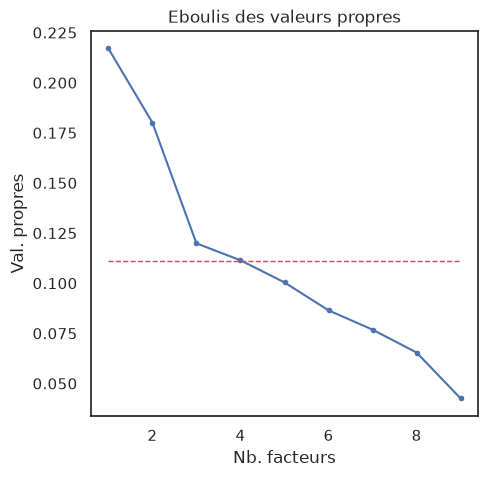

In [64]:
#librairie graphique
import matplotlib.pyplot as plt
#éboulis des v.p.
fix,ax = plt.subplots(figsize=(5,5))
ax.plot(range(1,Hmax+1),acm.eig_[0],".-")
ax.set_xlabel("Nb. facteurs")
ax.set_ylabel("Val. propres")
plt.title("Eboulis des valeurs propres")
#seuil - Règle de Kaiser
ax.plot([1,Hmax],[1/p,1/p],"r--",linewidth=1)
plt.show()

In [65]:
#récupérer les valeurs propres supérieur à (1/p)
lambada = acm.eig_[0][acm.eig_[0]>1/p]
print(lambada)
#appliquer la correction
lambada_prim = ((p/(p-1))*(lambada-1/p))**2
print(lambada_prim)
#faire la somme
S_prim = np.sum(lambada_prim)
print(S_prim)

[0.21705905 0.18006973 0.11985768 0.11142755]
[1.42065962e-02 6.01841445e-03 9.68234296e-05 1.26728915e-07]
0.020321960766117395


In [66]:
#et produire les pourcentages
percent_prim = lambada_prim/S_prim*100
#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_prim,np.cumsum(percent_prim)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1)))


          Val.P          %     Cumul %
1  1.420660e-02  69.907605   69.907605
2  6.018414e-03  29.615324   99.522929
3  9.682343e-05   0.476447   99.999376
4  1.267289e-07   0.000624  100.000000


In [67]:
#somme corrigée de Greenacre (S’’)
S2nd = p/(p-1)*(np.sum(acm.eig_[0]**2)-(M-p)/(p**2))
print(S2nd)
#pourcentage corrigé Greenacre
percent_2nd = lambada_prim/S2nd

#affichage
print(pd.DataFrame(np.transpose(np.array([lambada_prim,percent_2nd,np.cumsum(percent_2nd)])),columns=['Val.P','%','Cumul %'],index=range(1,len(lambada)+1)))

0.027843707676079906
          Val.P         %   Cumul %
1  1.420660e-02  0.510226  0.510226
2  6.018414e-03  0.216150  0.726376
3  9.682343e-05  0.003477  0.729854
4  1.267289e-07  0.000005  0.729858


In [68]:
len(acm.col_coord_[:,:2])

18

In [69]:
#affichage des coordonnées
print(pd.DataFrame(acm.col_coord_[:,:2],index=X.columns,columns=['Coord.F1','Coord.F2']))

         Coord.F1  Coord.F2
PE6_Non  0.150417 -0.110579
PE6_Oui -0.884804  0.650467
SH1_Non -0.302154 -0.023498
SH1_Oui  1.234892  0.096034
SH2_Non -0.271641 -0.042601
SH2_Oui  1.401094  0.219730
SH3_Non -0.723838  0.175528
SH3_Oui  0.559330 -0.135636
SH4_Non  0.322052  0.148144
SH4_Oui -0.644104 -0.296289
SH5_Non  0.071513  0.338885
SH5_Oui -0.238376 -1.129617
SH6_Non -0.061680  0.410696
SH6_Oui  0.226983 -1.511360
SH7_Non -0.322826  0.055810
SH7_Oui  1.250952 -0.216263
SH8_Non  0.096931  0.467204
SH8_Oui -0.201515 -0.971292


In [121]:
df_rows = acm.row_topandas()


df_cols = acm.col_topandas()
dict_lab_short = {}
for lab in df_cols.index:
    lab_split = lab.split("_")
    dict_lab_short[lab] = "_".join(lab_split[1:])

df_cols["label"] = df_cols.index.map(dict_lab_short.get)
df_cols[['col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)
df_dim1_2 = df_cols[['col_contrib_dim1', 'col_contrib_dim2','col_cos2_dim1',
       'col_cos2_dim2']].sort_values('col_contrib_dim1', ascending=False)
df_dim1_2["cum_cos2"] = df_dim1_2.col_cos2_dim1 + df_dim1_2.col_cos2_dim2
df_dim1_2.sort_values('cum_cos2', ascending=False)


,col_coord_dim1,col_coord_dim2,col_coord_dim3,col_coord_dim4,col_coord_dim5,col_coord_dim6,col_coord_dim7,col_coord_dim8,col_coord_dim9,col_contrib_dim1,...,col_cos2_dim1,col_cos2_dim2,col_cos2_dim3,col_cos2_dim4,col_cos2_dim5,col_cos2_dim6,col_cos2_dim7,col_cos2_dim8,col_cos2_dim9,label
PE6_PE6_Non,0.150417,-0.110579,0.121480,0.122278,-0.307840,0.011960,0.069680,-0.071207,-0.024568,0.989887,...,0.133089,0.071928,0.086808,0.087952,0.557443,0.000841,0.028560,0.029826,0.003550,PE6_Non
PE6_PE6_Oui,-0.884804,0.650467,-0.714588,-0.719282,1.810823,-0.070356,-0.409881,0.418867,0.144516,5.822866,...,0.133089,0.071928,0.086808,0.087952,0.557443,0.000841,0.028560,0.029826,0.003550,PE6_Oui
SH1_SH1_Non,-0.302154,-0.023498,0.303503,-0.082502,0.098800,0.052463,0.086371,-0.095834,-0.157331,3.754739,...,0.373128,0.002257,0.376465,0.027818,0.039895,0.011249,0.030488,0.037535,0.101165,SH1_Non
SH1_SH1_Oui,1.234892,0.096034,-1.240402,0.337182,-0.403792,-0.214414,-0.352994,0.391668,0.643005,15.345454,...,0.373128,0.002257,0.376465,0.027818,0.039895,0.011249,0.030488,0.037535,0.101165,SH1_Oui
SH2_SH2_Non,-0.271641,-0.042601,0.150081,-0.060705,-0.113264,-0.223225,-0.134391,0.062603,0.086177,3.163803,...,0.380594,0.009361,0.116179,0.019008,0.066169,0.257014,0.093157,0.020214,0.038305,SH2_Non
SH2_SH2_Oui,1.401094,0.219730,-0.774104,0.313112,0.584203,1.151369,0.693176,-0.322899,-0.444490,16.318564,...,0.380594,0.009361,0.116179,0.019008,0.066169,0.257014,0.093157,0.020214,0.038305,SH2_Oui
SH3_SH3_Non,-0.723838,0.175528,-0.357073,-0.179998,-0.236308,-0.003041,0.697630,0.080151,0.174648,11.690876,...,0.404864,0.023808,0.098524,0.025036,0.043150,0.000007,0.376077,0.004964,0.023570,SH3_Non
SH3_SH3_Oui,0.559330,-0.135636,0.275920,0.139090,0.182602,0.002350,-0.539078,-0.061935,-0.134956,9.033858,...,0.404864,0.023808,0.098524,0.025036,0.043150,0.000007,0.376077,0.004964,0.023570,SH3_Oui
SH4_SH4_Non,0.322052,0.148144,-0.113518,-0.522320,-0.158256,-0.182769,0.007513,0.010023,-0.173276,3.539488,...,0.207435,0.043894,0.025773,0.545637,0.050090,0.066809,0.000113,0.000201,0.060049,SH4_Non
SH4_SH4_Oui,-0.644104,-0.296289,0.227037,1.044641,0.316511,0.365537,-0.015026,-0.020046,0.346552,7.078976,...,0.207435,0.043894,0.025773,0.545637,0.050090,0.066809,0.000113,0.000201,0.060049,SH4_Oui


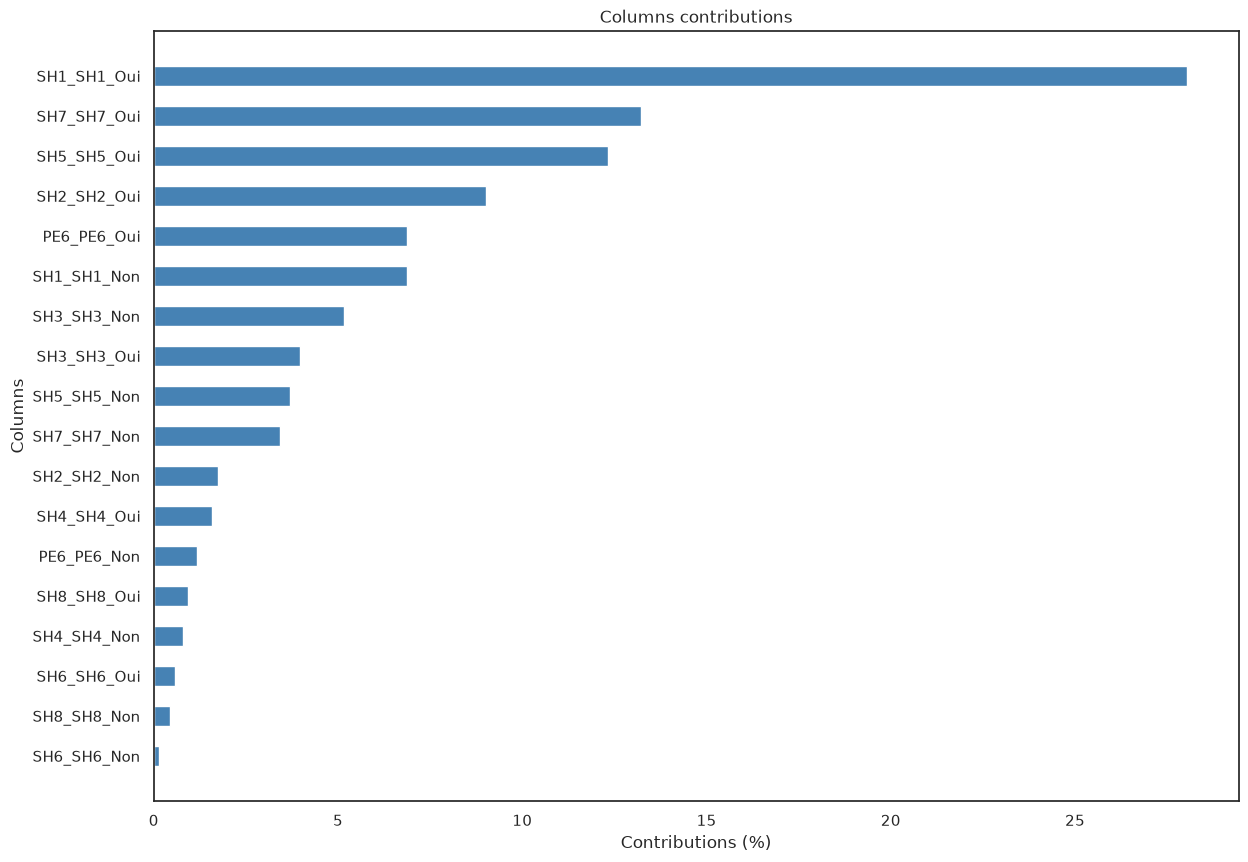

In [146]:
#ou bien graphiquement
acm.plot_col_contrib(num_axis=3, short_labels=False)

In [ ]:
df

/tmp/ipykernel_72753/3998452038.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(acm.col_coord_[i,dim_x-1],acm.col_coord_[i,dim_y-1],df_cols.label[i],color="black", alpha=(acm.col_cos2_[i,dim_x-1]+acm.col_cos2_[i,dim_y-1]))


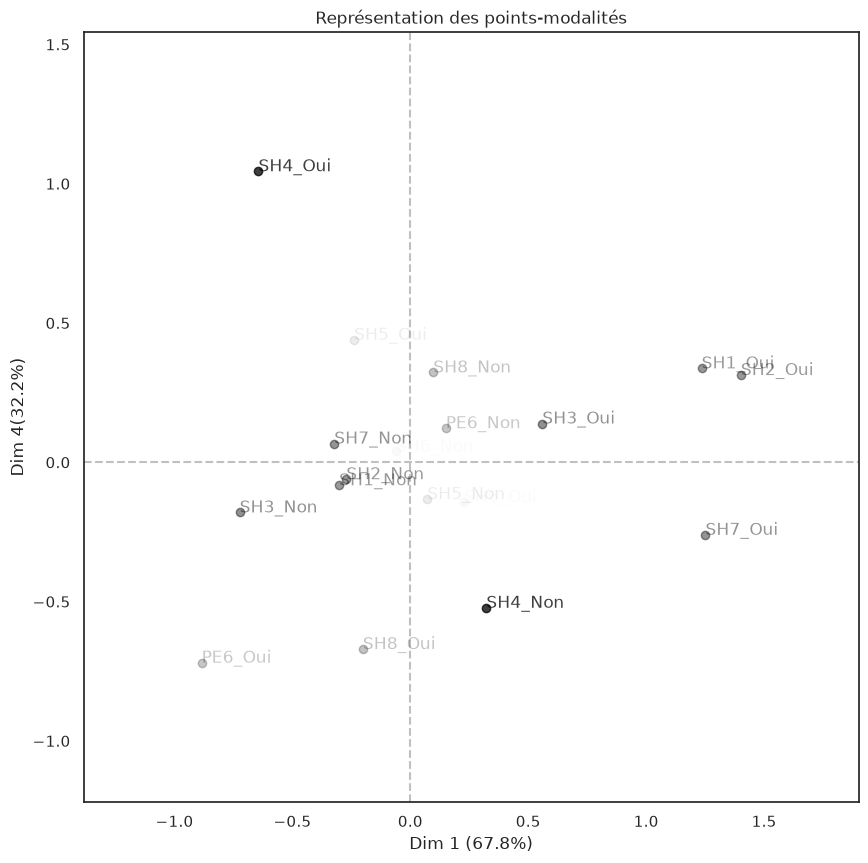

In [160]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))

dim_x = 1
dim_y = 4
min_abs = np.min(df_cols[f"col_coord_dim{dim_x}"])-0.5
max_abs = np.max(df_cols[f"col_coord_dim{dim_x}"])+0.5
min_ord = np.min(df_cols[f"col_coord_dim{dim_y}"])-0.5
max_ord = np.max(df_cols[f"col_coord_dim{dim_y}"])+0.5




ax.axis([min_abs, max_abs,min_ord, max_ord])
ax.plot([min_abs,max_abs],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[min_ord, max_ord],color='silver',linestyle='--')

ax.set_xlabel(f"Dim {dim_x} (67.8%)")
ax.set_ylabel(f"Dim {dim_y}(32.2%)")

plt.title("Représentation des points-modalités")
for i in range(df_cols.shape[dim_x-1]):
    ax.scatter(acm.col_coord_[i,dim_x-1],acm.col_coord_[i,dim_y-1],color="black", alpha=(acm.col_cos2_[i,dim_x-1]+acm.col_cos2_[i,dim_y-1]))
    ax.text(acm.col_coord_[i,dim_x-1],acm.col_coord_[i,dim_y-1],df_cols.label[i],color="black", alpha=(acm.col_cos2_[i,dim_x-1]+acm.col_cos2_[i,dim_y-1]))

plt.show()

In [149]:
print(pd.DataFrame(np.cumsum(acm.col_cos2_[:,:4],axis=1),index=df_cols.index,columns=['Cos2.F1','Cum(Cos2).F2', 'Cum(Cos2).F3', 'Cum(Cos2).F4']))

              Cos2.F1  Cum(Cos2).F2  Cum(Cos2).F3  Cum(Cos2).F4
PE6_PE6_Non  0.133089      0.205018      0.291826      0.379778
PE6_PE6_Oui  0.133089      0.205018      0.291826      0.379778
SH1_SH1_Non  0.373128      0.375385      0.751850      0.779668
SH1_SH1_Oui  0.373128      0.375385      0.751850      0.779668
SH2_SH2_Non  0.380594      0.389955      0.506134      0.525141
SH2_SH2_Oui  0.380594      0.389955      0.506134      0.525141
SH3_SH3_Non  0.404864      0.428672      0.527196      0.552232
SH3_SH3_Oui  0.404864      0.428672      0.527196      0.552232
SH4_SH4_Non  0.207435      0.251329      0.277101      0.822739
SH4_SH4_Oui  0.207435      0.251329      0.277101      0.822739
SH5_SH5_Non  0.017047      0.399857      0.572734      0.630797
SH5_SH5_Oui  0.017047      0.399857      0.572734      0.630797
SH6_SH6_Non  0.014000      0.634709      0.642461      0.648017
SH6_SH6_Oui  0.014000      0.634709      0.642461      0.648017
SH7_SH7_Non  0.403840      0.415910     

In [150]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(7,7))
ax.axis([np.mean(df_col.,+4,-3,+3])
min_absice

ax.plot([-3,+3],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[-3,+3],color='silver',linestyle='--')
ax.set_xlabel("Dim.1 (67.8%)")
ax.set_ylabel("Dim.2 (32.2%)")
plt.title("Représentation des points-modalités")
for i in range(df_cols.shape[0]):
    ax.text(acm.col_coord_[i,0],acm.col_coord_[i,1],df_cols.index[i],color='dodgerblue')
plt.show()

SyntaxError: closing parenthesis ']' does not match opening parenthesis '(' (2026828954.py, line 3)

In [151]:
df_os.columns

Index(['PE6', 'SH1', 'SH2', 'SH3', 'SH4', 'SH5', 'SH6', 'SH7', 'SH8',
       'label_recherche_1'],
      dtype='object')

In [159]:
contrib12

,0,1,2
PE6_Non,0.989887,0.644881,1.169270
PE6_Oui,5.822866,3.793418,6.878059
SH1_Non,3.754739,0.027372,6.860544
SH1_Oui,15.345454,0.111868,28.038746
SH2_Non,3.163803,0.093797,1.748984
SH2_Oui,16.318564,0.483796,9.021077
SH3_Non,11.690876,0.828697,5.152170
SH3_Oui,9.033858,0.640357,3.981222
SH4_Non,3.539488,0.902809,0.796404
SH4_Oui,7.078976,1.805618,1.592808


In [153]:
df_os

,PE6,SH1,SH2,SH3,SH4,SH5,SH6,SH7,SH8,label_recherche_1
q45_clé,,,,,,,,,,
2DRU-P3AV,PE6_Oui,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Psychologie
2JQN-P9PA,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Psychologie
2QNC-8AAQ,PE6_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Oui,SH6_Non,SH7_Oui,SH8_Non,"Individus, normes, société"
2Y89-7BR9,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non,Psychologie
32TW-JLY5,PE6_Oui,SH1_Non,SH2_Non,SH3_Non,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Sciences informatiques
...,...,...,...,...,...,...,...,...,...,...
YL4Q-KQAK,PE6_Non,SH1_Oui,SH2_Non,SH3_Oui,SH4_Non,SH5_Non,SH6_Non,SH7_Non,SH8_Oui,Histoires sociales du politique
YTMC-B4DP,PE6_Non,SH1_Non,SH2_Non,SH3_Oui,SH4_Oui,SH5_Non,SH6_Non,SH7_Non,SH8_Non,Psychologie sociale
ZB5S-ABHN,PE6_Non,SH1_Non,SH2_Non,SH3_Non,SH4_Oui,SH5_Oui,SH6_Non,SH7_Non,SH8_Non,Psychologie


In [154]:
#contrib12.loc[np.unique(df_os.iloc[:,1])][0]
contrib12
df_cols.index

Index(['PE6_PE6_Non', 'PE6_PE6_Oui', 'SH1_SH1_Non', 'SH1_SH1_Oui',
       'SH2_SH2_Non', 'SH2_SH2_Oui', 'SH3_SH3_Non', 'SH3_SH3_Oui',
       'SH4_SH4_Non', 'SH4_SH4_Oui', 'SH5_SH5_Non', 'SH5_SH5_Oui',
       'SH6_SH6_Non', 'SH6_SH6_Oui', 'SH7_SH7_Non', 'SH7_SH7_Oui',
       'SH8_SH8_Non', 'SH8_SH8_Oui'],
      dtype='object')

In [168]:
acm.col_contrib_[:,[0,2]]

array([[ 0.98988727,  1.16927004],
       [ 5.82286627,  6.87805905],
       [ 3.75473867,  6.86054426],
       [15.34545371, 28.03874609],
       [ 3.1638033 ,  1.7489843 ],
       [16.31856441,  9.02107693],
       [11.69087566,  5.15217011],
       [ 9.03385847,  3.98122236],
       [ 3.53948811,  0.79640398],
       [ 7.07897622,  1.59280795],
       [ 0.20137404,  3.69832469],
       [ 0.67124682, 12.32774897],
       [ 0.1531341 ,  0.15355139],
       [ 0.56353349,  0.56506913],
       [ 4.24047469,  3.41467407],
       [16.43183942, 13.23186203],
       [ 0.32474909,  0.44478989],
       [ 0.67513626,  0.92469476]])

In [170]:
#récupération des contribution sous une forme exploitable - 2 facteurs
contrib12 = pd.DataFrame(acm.col_contrib_[:,[0,2]],index=X.columns)
print(contrib12)

#**calcul des carrés des rapports de corrélation par variable sur les 2 facteurs**
#structure pour les eta2
#structure pour les eta2
cols=len(table.columns)
eta2 = np.zeros((cols,2))
#pour chaque facteur
for h in range(2):
    #pour chaque variable
    for j in range(cols):
        eta2[j,h] = (p*acm.eig_[0][h]*np.sum(contrib12.loc[np.unique(table.iloc[:,j])][h]))/100
            #affichage

print(pd.DataFrame(eta2,index=table.columns[:],columns=['F1','F2']))



                 0          1
PE6_Non   0.989887   1.169270
PE6_Oui   5.822866   6.878059
SH1_Non   3.754739   6.860544
SH1_Oui  15.345454  28.038746
SH2_Non   3.163803   1.748984
SH2_Oui  16.318564   9.021077
SH3_Non  11.690876   5.152170
SH3_Oui   9.033858   3.981222
SH4_Non   3.539488   0.796404
SH4_Oui   7.078976   1.592808
SH5_Non   0.201374   3.698325
SH5_Oui   0.671247  12.327749
SH6_Non   0.153134   0.153551
SH6_Oui   0.563533   0.565069
SH7_Non   4.240475   3.414674
SH7_Oui  16.431839  13.231862
SH8_Non   0.324749   0.444790
SH8_Oui   0.675136   0.924695
                           F1        F2
q24_research_fields                    
PE6                  0.133089  0.130417
SH1                  0.373128  0.565588
SH2                  0.380594  0.174543
SH3                  0.404864  0.148018
SH4                  0.207435  0.038720
SH5                  0.017047  0.259723
SH6                  0.014000  0.011646
SH7                  0.403840  0.269778
SH8                  0.019533 

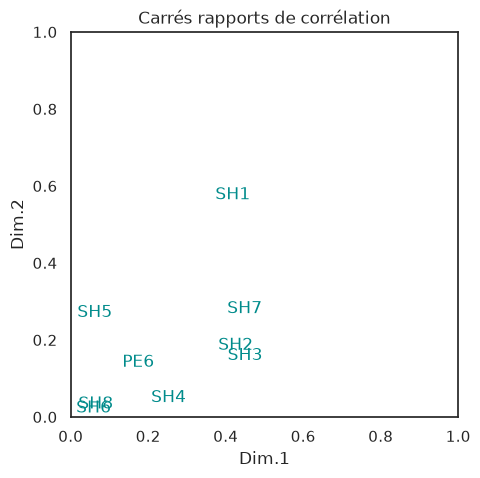

In [171]:
fix,ax = plt.subplots(figsize=(5,5))
ax.axis([0,+1,0,+1])
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Carrés rapports de corrélation")
for i in range(cols):
    ax.text(eta2[i,0],eta2[i,1],df_os.columns[i],color='darkcyan')
plt.show()

In [130]:
df_coord = pd.DataFrame(acm.row_coord_[:,:2],index=X.index,columns=['F1','F2'])
df_coord['champ'] = Dillustratives.label_recherche_1
print(df_coord)

                 F1        F2                                   champ
q45_clé                                                              
2DRU-P3AV -0.725628  0.454609                             Psychologie
2JQN-P9PA -0.478739  0.255336                             Psychologie
2QNC-8AAQ  0.725693 -0.134224              Individus, normes, société
2Y89-7BR9 -0.552644 -0.129178                             Psychologie
32TW-JLY5 -0.495210  0.570979                  Sciences informatiques
...             ...       ...                                     ...
YL4Q-KQAK  0.353093 -0.055128         Histoires sociales du politique
YTMC-B4DP -0.172717  0.173860                     Psychologie sociale
ZB5S-ABHN -0.552644 -0.129178                             Psychologie
ZBFK-V8BA -0.495210  0.570979                  Sciences informatiques
ZGPH-2FPH -0.120516 -0.962549  Etudes sociales des oeuvres culturelle

[117 rows x 3 columns]


In [131]:
#calcul des moyennes conditionnelles
GBar = pd.pivot_table(df_coord,values=['F1','F2'],index="champ",aggfunc='mean')
print(GBar)

                                              F1        F2
champ                                                     
Etudes sociales des oeuvres culturelle -0.143084 -0.522874
Histoires de l'art et des sciences     -0.164233 -0.297254
Histoires sociales du politique         0.391262 -0.296679
Individus, normes, société              0.762340  0.282983
Psychologie                            -0.493311  0.185360
Psychologie sociale                    -0.172717  0.173860
Recherche et création                  -0.374362  0.039332
Sciences info. com.                     0.033011  0.310158
Sciences informatiques                 -0.495210  0.570979
Sociétés, espaces et environnements     0.394776  0.229176


In [132]:
#coordonnées factorielles des modalités - Solution 1
Gv1 = GBar.values/np.sqrt(acm.eig_[0][:2])
Gv1 = pd.DataFrame(Gv1,index=GBar.index,columns=GBar.columns)
print(Gv1)

                                              F1        F2
champ                                                     
Etudes sociales des oeuvres culturelle -0.307116 -1.232188
Histoires de l'art et des sciences     -0.352509 -0.700498
Histoires sociales du politique         0.839806 -0.699144
Individus, normes, société              1.636289  0.666867
Psychologie                            -1.058843  0.436814
Psychologie sociale                    -0.370721  0.409713
Recherche et création                  -0.803531  0.092689
Sciences info. com.                     0.070856  0.730908
Sciences informatiques                 -1.062920  1.345550
Sociétés, espaces et environnements     0.847349  0.540068


/tmp/ipykernel_72753/3551414018.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.scatter(Gv1.loc[i][0],Gv1.loc[i][1],color='red')
/tmp/ipykernel_72753/3551414018.py:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(Gv1.loc[i][0],Gv1.loc[i][1],i,color='red')


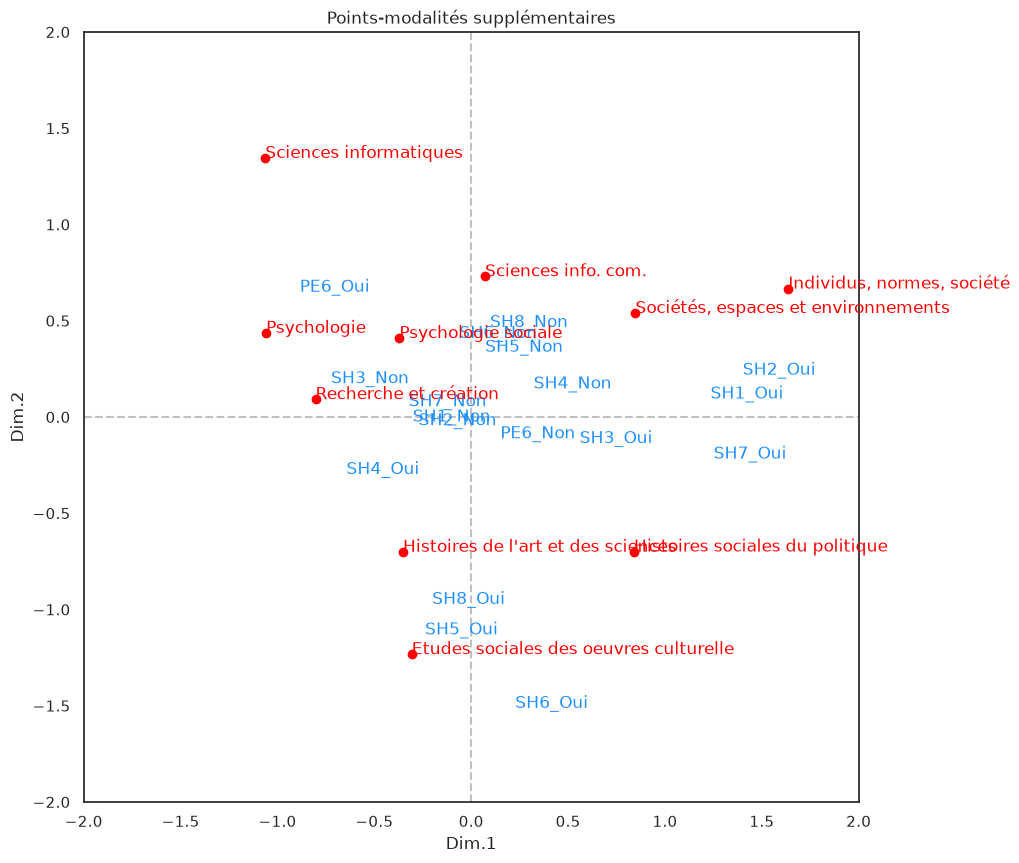

In [135]:
#représentation dans le plan
fix,ax = plt.subplots(figsize=(10,10))
ax.axis([-2,+2,-2,+2])
ax.plot([-2,+2],[0,0],color='silver',linestyle='--')
ax.plot([0,0],[-2,+2],color='silver',linestyle='--')
ax.set_xlabel("Dim.1")
ax.set_ylabel("Dim.2")
plt.title("Points-modalités supplémentaires")
#modalités actives
for i in range(X.shape[1]):
    ax.text(acm.col_coord_[i,0],acm.col_coord_[i,1],X.columns[i],color='dodgerblue')
#modalités illustratives de la variable "fonction"
for i in Gv1.index:
    ax.scatter(Gv1.loc[i][0],Gv1.loc[i][1],color='red')
    ax.text(Gv1.loc[i][0],Gv1.loc[i][1],i,color='red')
plt.show()

In [477]:
print(df0.auto_lab_research_cluster.value_counts().to_markdown())

| auto_lab_research_cluster                                                                                                                                       |   count |
|:----------------------------------------------------------------------------------------------------------------------------------------------------------------|--------:|
| ["SH4 L'esprit humain et sa complexité", 'SH8 Études des cultures et des arts', "SH6 L'étude du passé humain"]                                                  |      18 |
| ["SH4 L'esprit humain et sa complexité", 'LS5 Neurosciences et troubles du système nerveux', 'LS4 Physiologie de la santé, de la maladie et du vieillissement'] |      17 |
| ['SH2 Institutions, gouvernance et systèmes juridiques', 'SH1 Individus, marchés et organisations', 'SH7 Mobilité humaine, environnement et espace']            |      16 |
| ['SH8 Études des cultures et des arts', "SH6 L'étude du passé humain", 'SH1 Individus, marchés et organisations']               